# Réplica parcial de *Patches Are All You Need?* (ConvMixer) en CIFAR-10
**Tópicos en Aprendizaje Automático — UNAJ, Doctorado en Ciencia y Tecnología · Trabajo Final Integrador**
Marcos David Kantor · Docentes: Dr. Ing. Martín Morales y Dr. Ing. Marcelo Cappelletti

> Trockman, A. y Kolter, J. Z. (2023). Patches are all you need? *Transactions on Machine Learning Research*. https://doi.org/10.48550/arXiv.2201.09792

**Pregunta del artículo.** ¿El buen desempeño de los Vision Transformers se debe a la autoatención o a que la
imagen entra cortada en *parches*? El ConvMixer conserva los parches y el diseño isotrópico del ViT, pero mezcla la
información sólo con convoluciones.

**Qué se replica.** El experimento de CIFAR-10 del Apéndice B: la arquitectura (Fig. 7), la receta de entrenamiento
(AdamW, tasa triangular, recorte de gradiente, escalado aleatorio), las ablaciones de **tamaño de núcleo** y de
**tamaño de parche**, y la comparación con una **ResNet** entrenada con la misma receta. Para ubicar el modelo en el
programa del curso se agregan modelos de las cinco unidades:

| Unidad | Modelo en este notebook |
|---|---|
| U1 | partición entrenamiento/validación/test y validación cruzada de 5 pliegues |
| U2 | asociador lineal resuelto con la seudoinversa (SVD, Tikhonov) y perceptrón simple multiclase |
| U3 | perceptrón multicapa entrenado con retropropagación |
| U4 | **ConvMixer** (paper) y ResNet |
| U5 | Extreme Learning Machine (SVD) y ELM multicapa (ML-ELM) |

**Objetivos de aprendizaje.** Al terminar el notebook deberías poder: (1) explicar qué hace cada bloque del
ConvMixer y por qué; (2) verificar que una implementación coincide con la de un artículo antes de entrenar;
(3) distinguir validación de test y no "espiar" el test; (4) explicar por qué una CNN supera a modelos lineales,
ELM y MLP en imágenes (sesgo inductivo); (5) comparar resultados propios con los publicados y explicar las diferencias.

**Cómo correrlo.**
* `MODO = "resultados"` (por defecto): no entrena; lee los resultados guardados en `results/` (los del informe) y rehace tablas y figuras. Tarda segundos.
* `MODO = "rapido"`: entrena todo sobre 5 000 imágenes y 1 época (unos 10 min en CPU) para ver que el código funciona.
* `MODO = "completo"`: reproduce los experimentos del informe (unas 5 h en CPU de 8 núcleos; unos 15 min en una GPU de Colab).

In [1]:
# --- Configuración (en Google Colab: Entorno de ejecución → GPU y descomentar la clonación) ---
# !git clone https://github.com/marcoskantor/unaj-aprendizaje-automatico.git
# %cd unaj-aprendizaje-automatico
MODO = "resultados"   # "resultados" | "rapido" | "completo"

import sys, json, time
from pathlib import Path
import numpy as np, torch, matplotlib.pyplot as plt
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
from datos import cargar_cifar10, normalizar, CLASES
from modelos import ConvMixer, ResNetChica, MLP, params_convmixer, contar_parametros, pinv_ridge, ELM
from entrenamiento import Config, entrenar, evaluar, throughput
import experimentos as E
CFG = json.loads((RAIZ / "config.json").read_text(encoding="utf8"))
print("torch", torch.__version__, "| GPU:", torch.cuda.is_available(), "| modo:", MODO)

torch 2.15.0+cpu | GPU: False | modo: resultados


> **🔎 Qué observar.** La salida dice si hay GPU. En CPU, el modo `"completo"` tarda unas 5 horas; en una GPU de Colab, unos 15 minutos.
> Todos los hiperparámetros salen de `config.json`: no hay números "mágicos" escondidos en el código, que es lo que permite que otra persona repita el experimento.

## 1. Datos: CIFAR-10 (U1: estructura de un sistema de AA)
60 000 imágenes en color de $32\times32$, 10 clases balanceadas (50 000 de entrenamiento y 10 000 de prueba).
**Fuente:** Krizhevsky (2009), página oficial <https://www.cs.toronto.edu/~kriz/cifar-10.html>; archivo
<https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz> (versión *python*, 170 MB). `src/datos.py` lo descarga
automáticamente la primera vez y lo lee sin torchvision.
Se apartan **5 000 imágenes de entrenamiento como validación** (semilla fija). El test se usa **una sola vez**, al
final; el artículo, en cambio, no informa un conjunto de validación (ver informe, §5).

**Preprocesamiento.** Estandarización por canal con la media y el desvío del entrenamiento. Aumentación *sólo* en
entrenamiento: escalado aleatorio (la aumentación que el paper encontró más importante), recorte con relleno y espejo
horizontal.

entrenamiento: (50000, 32, 32, 3)  test: (10000, 32, 32, 3)  imágenes por clase: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


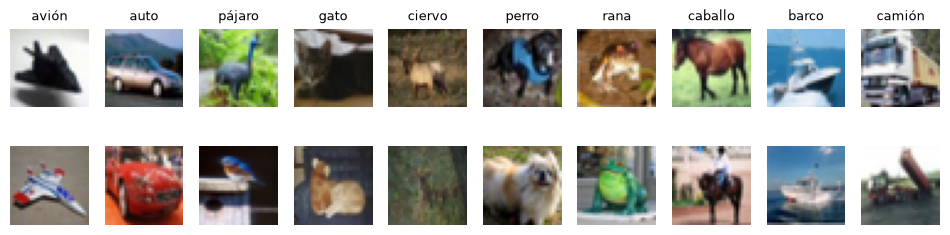

In [2]:
x_tr, y_tr, x_te, y_te = cargar_cifar10()
print("entrenamiento:", x_tr.shape, " test:", x_te.shape, " imágenes por clase:", np.bincount(y_tr))
fig, axs = plt.subplots(2, 10, figsize=(12, 2.8))
for c in range(10):
    for f in range(2):
        axs[f, c].imshow(x_tr[np.flatnonzero(y_tr == c)[f]]); axs[f, c].axis("off")
    axs[0, c].set_title(CLASES[c], fontsize=9)
plt.show()

> **🔎 Qué observar.** Las clases están balanceadas (5 000 imágenes por clase), así que la *exactitud* es una métrica razonable (U1); con clases desbalanceadas habría que mirar F1 o la exactitud balanceada.
> Con $32\times32$ píxeles, a veces cuesta reconocer los objetos incluso a simple vista: por eso CIFAR-10 es más difícil de lo que parece.
>
> **💭 Para pensar.** ¿Qué clases esperás que el modelo confunda? (Se responde en §5.4.)

## 2. El modelo (U4)
Transcripción literal de la Fig. 7 del artículo (`src/modelos.py`):

```python
def ConvMixer(dim, depth, kernel_size=9, patch_size=7, n_classes=1000):
    return nn.Sequential(
        nn.Conv2d(3, dim, kernel_size=patch_size, stride=patch_size), nn.GELU(), nn.BatchNorm2d(dim),
        *[nn.Sequential(
            Residual(nn.Sequential(nn.Conv2d(dim, dim, kernel_size, groups=dim, padding="same"),
                                   nn.GELU(), nn.BatchNorm2d(dim))),
            nn.Conv2d(dim, dim, kernel_size=1), nn.GELU(), nn.BatchNorm2d(dim)) for i in range(depth)],
        nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(), nn.Linear(dim, n_classes))
```

* **Embebido de parches**: convolución $p\times p$ con paso $p$ (cada parche se proyecta a $h$ canales).
* **Depthwise** $k\times k$ (`groups=dim`): un filtro por canal, mezcla *espacial*, con conexión residual.
* **Pointwise** $1\times1$: mezcla entre *canales*.
* Sin submuestreo: la resolución interna $32/p$ es la misma en las $d$ capas (diseño **isotrópico**).

Primera verificación: el número de parámetros de PyTorch debe coincidir con la **ecuación (4)** del artículo,
$h[d(k^2+h+6)+c\,p^2+n+3]+n$, y con la Tabla 4 (por ejemplo, ConvMixer-256/8 con $k=9$ y $p=2$ tiene 709 k).

In [3]:
for h, d, k, p in [(256, 8, 9, 1), (256, 8, 9, 2), (256, 8, 3, 2), (128, 8, 9, 2), (128, 8, 3, 2), (128, 8, 9, 4)]:
    m = ConvMixer(h, d, k, p, 10)
    print(f"ConvMixer-{h}/{d} k={k} p={p}:  PyTorch = {contar_parametros(m):>8,}   ec.(4) = {params_convmixer(h, d, k, p):>8,}")
print("ResNet (32-64-128):", f"{contar_parametros(ResNetChica((32, 64, 128))):,}", "parámetros")

ConvMixer-256/8 k=9 p=1:  PyTorch =  706,570   ec.(4) =  706,570
ConvMixer-256/8 k=9 p=2:  PyTorch =  708,874   ec.(4) =  708,874
ConvMixer-256/8 k=3 p=2:  PyTorch =  561,418   ec.(4) =  561,418
ConvMixer-128/8 k=9 p=2:  PyTorch =  223,370   ec.(4) =  223,370
ConvMixer-128/8 k=3 p=2:  PyTorch =  149,642   ec.(4) =  149,642
ConvMixer-128/8 k=9 p=4:  PyTorch =  227,978   ec.(4) =  227,978
ResNet (32-64-128): 308,650 parámetros


> **🔎 Qué observar.** Las dos columnas tienen que coincidir. Si no coinciden, la implementación no es la del paper. Es la primera verificación de una réplica: antes de entrenar, comprobar que el modelo es el mismo (Trockman y Kolter, 2023, ec. 4).
> El término que más pesa es $d\,h^2$ (las convoluciones $1\times1$). Por eso pasar de $h=256$ a $h=128$ divide los parámetros por algo más de 3, mientras que cambiar $k$ casi no los mueve.
>
> **💭 Para pensar.** ¿Por qué el parche $p$ casi no cambia la cantidad de parámetros, pero sí cambia mucho el tiempo de cómputo? (Pista: la resolución interna es $32/p$.)

**Campo receptivo.** Con parche $p$ y $d$ capas de núcleo $k$, un píxel de salida "ve" $p\,[1+d(k-1)]$ píxeles de la
imagen: con $p=2$, $d=8$ son 34 píxeles para $k=3$ y 130 para $k=9$. Con $k=9$ cada posición mezcla información de
toda la imagen ya en la segunda capa, como lo haría la atención. Esa es la intuición detrás de los núcleos grandes.

## 3. Receta de entrenamiento (U3–U4: descenso por gradiente estocástico)
`src/entrenamiento.py`: AdamW, tasa de aprendizaje **triangular** (0 → $\eta_{max}$ en el 40 % de los pasos →
$\eta_{max}/20$ en el 80 % → 0, como en el repositorio oficial), **recorte de la norma del gradiente** en 1,0,
*weight decay* $10^{-2}$, lotes de 128. En CPU se usa `channels_last`, que acelera unas 2,5 veces la convolución
depthwise.

**Diferencias con el artículo, por cómputo**: 10 épocas en lugar de 200; $h=128$ en lugar de 256; $p=2$ en lugar de
$p=1$ (con $p=1$ una época tarda unas 3,5 h en esta CPU); sin RandAugment, mixup, CutMix ni *random erasing*.

{
 "epocas": 10,
 "lote": 128,
 "lr_max": 0.01,
 "weight_decay": 0.01,
 "clip": 1.0,
 "escalado": true,
 "recorte_espejo": true,
 "borrado": 0.0,
 "mixup": 0.0,
 "suavizado": 0.0,
 "semilla": 0
}


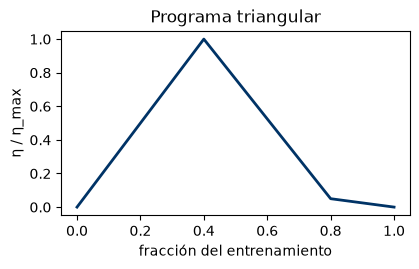

In [4]:
cfg = dict(CFG["entrenamiento_cnn"]); print(json.dumps(cfg, indent=1))
total = 100
lr = [float(np.interp(t, [0, total * 2 / 5, total * 4 / 5, total], [0, 1, 1 / 20, 0])) for t in range(total + 1)]
plt.figure(figsize=(4.5, 2.4)); plt.plot(np.linspace(0, 1, total + 1), lr, color="#003366", lw=2)
plt.xlabel("fracción del entrenamiento"); plt.ylabel("η / η_max"); plt.title("Programa triangular"); plt.show()

> **🔎 Qué observar.** La tasa de aprendizaje sube de forma lineal (calentamiento), baja y termina en cero. Arrancar con un $\eta$ chico evita que BatchNorm y AdamW se desestabilicen en los primeros pasos; terminar cerca de cero ayuda a asentarse en un mínimo (U3: el descenso por gradiente como problema de optimización).

## 4. Experimentos
`src/experimentos.py` entrena cada modelo, evalúa una sola vez en test y guarda `results/<nombre>.json`
(historia, exactitud, matriz de confusión, parámetros, velocidad) y los pesos (`.pt`). La celda siguiente
**sólo entrena** si `MODO` no es `"resultados"`.

In [5]:
if MODO == "rapido":
    E.correr_clasicos(rapido=True)
    for n in CFG["orden_cnn"]:
        E.correr_cnn(n, rapido=True)
elif MODO == "completo":
    E.correr_clasicos()
    for n in CFG["orden_cnn"]:
        E.correr_cnn(n)
sufijo = "_rapido" if MODO == "rapido" else ""
leer = lambda n: json.loads((RAIZ / "results" / f"{n}{sufijo}.json").read_text(encoding="utf8"))
cnn = {n: leer(n) for n in CFG["orden_cnn"]}
cla = leer("clasicos")

> **🔎 Qué observar.** En modo `"resultados"` esta celda sólo lee los JSON. Cada archivo guarda la historia por época, la exactitud de test, la matriz de confusión, la cantidad de parámetros y la velocidad. Así, el informe y las diapositivas se generan desde los mismos números (`src/figuras.py`).

## 5. Resultados
### 5.1 Tabla comparativa (todas las unidades)

In [6]:
import pandas as pd
filas = []
for n, r in cnn.items():
    filas.append(["U4", CFG["cnn"][n]["rol"], r["parametros"], 100 * r["acc_test"], r["throughput_img_s"], r["minutos"]])
filas += [["U3", "MLP 3072-1024-512-10", cla["mlp"]["parametros"], 100 * cla["mlp"]["acc_test"], cla["mlp"]["throughput_img_s"], np.nan],
          ["U5", f"ELM (L={cla['elm']['L_mejor']})", cla["elm"]["parametros"], 100 * cla["elm"]["acc_test"], np.nan, np.nan],
          ["U5", "ML-ELM", np.nan, 100 * cla["ml_elm"]["acc_test"], np.nan, np.nan],
          ["U2", f"Seudoinversa (λ={cla['lineal_seudoinversa']['lambda_cv']:g} por CV)", 30730, 100 * cla["lineal_seudoinversa"]["acc_test"], np.nan, np.nan],
          ["U2", "Perceptrón simple (promediado)", 30730, 100 * cla["perceptron"]["acc_test"], np.nan, np.nan]]
tabla = pd.DataFrame(filas, columns=["unidad", "modelo", "parámetros", "test (%)", "img/s CPU", "min"]).sort_values("test (%)", ascending=False)
tabla.style.format({"parámetros": "{:,.0f}", "test (%)": "{:.2f}", "img/s CPU": "{:.0f}", "min": "{:.1f}"}, na_rep="—").hide(axis="index")

unidad,modelo,parámetros,test (%),img/s CPU,min
U4,Ablación de núcleo: k=3,"149,642",84.63,531,71.9
U4,CNN piramidal tipo ResNet con la misma receta,"308,650",82.99,1572,31.5
U4,"ConvMixer-128/8 (modelo del paper, k=9, p=2)","223,370",82.68,422,110.4
U4,Ablación de parche: p=4,"227,978",78.66,1551,34.9
U3,MLP 3072-1024-512-10,"3,676,682",57.43,14147,—
U5,ELM (L=3000),"9,249,000",47.31,—,—
U2,Seudoinversa (λ=10000 por CV),"30,730",40.67,—,—
U5,ML-ELM,—,40.41,—,—
U2,Perceptrón simple (promediado),"30,730",40.31,—,—


> **🔎 Qué observar.** Hay que leer la tabla de abajo hacia arriba, siguiendo el programa: modelos lineales (U2), luego ELM (U5), MLP (U3) y CNN (U4). La columna de parámetros muestra que **más parámetros no implica más exactitud**: el MLP tiene muchos más que el ConvMixer y rinde mucho menos. Lo que cambia es el *sesgo inductivo*: la convolución supone localidad y comparte pesos.
>
> **💭 Para pensar.** ¿Qué columna le importaría más a un hospital que quiere correr el modelo en una computadora sin GPU?

### 5.2 Curvas de aprendizaje de las CNN

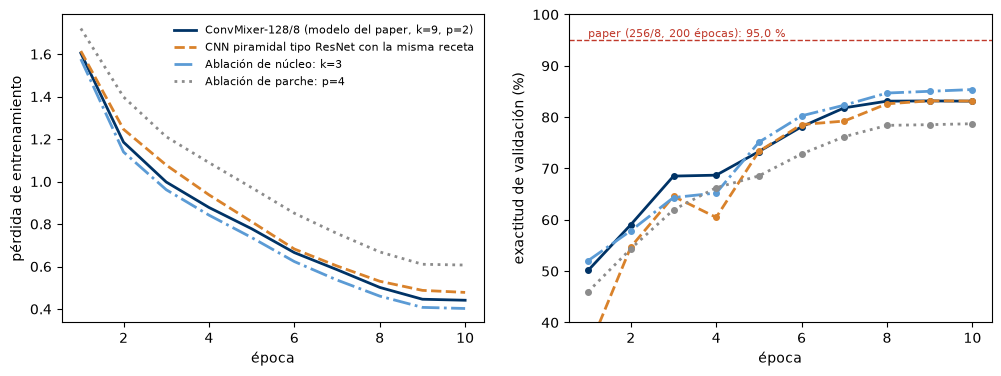

In [7]:
estilo = {"cm128_k9": ("#003366", "-"), "resnet": ("#D9822B", "--"), "cm128_k3": ("#5B9BD5", "-."), "cm128_p4": ("#8C8C8C", ":")}
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for n, r in cnn.items():
    c, ls = estilo[n]
    ep = [h["epoca"] for h in r["historia"]]
    axs[0].plot(ep, [h["perdida_entr"] for h in r["historia"]], color=c, ls=ls, lw=2, label=CFG["cnn"][n]["rol"])
    axs[1].plot(ep, [100 * h["acc_val"] for h in r["historia"]], color=c, ls=ls, lw=2, marker="o", ms=4)
axs[0].set(xlabel="época", ylabel="pérdida de entrenamiento"); axs[0].legend(fontsize=8, frameon=False)
axs[1].axhline(95.0, color="#C0392B", lw=1, ls="--"); axs[1].text(1, 95.6, "paper (256/8, 200 épocas): 95,0 %", color="#C0392B", fontsize=8)
axs[1].set(xlabel="época", ylabel="exactitud de validación (%)", ylim=(40, 100)); plt.show()

> **🔎 Qué observar.** (1) La pérdida de entrenamiento sigue bajando hasta el final: con más épocas todos los modelos mejorarían, como en el paper (200 épocas). (2) La validación se estabiliza en las últimas épocas, cuando la tasa de aprendizaje llega a cero. (3) La distancia a la línea roja es el costo de entrenar 20 veces menos y con un modelo 3 veces más chico.

### 5.3 Ablaciones frente al artículo (Tabla 4)
El artículo usa ConvMixer-256/8 y 200 épocas; aquí, 128/8 y 10 épocas. No se esperan los mismos números absolutos.
Lo que se compara es la **dirección y el tamaño relativo** de los efectos.

In [8]:
paper = {"cm128_k9": 95.00, "cm128_k3": 94.08, "cm128_p4": 92.61}
base = 100 * cnn["cm128_k9"]["acc_test"]
for n, ref in paper.items():
    a = 100 * cnn[n]["acc_test"]
    print(f"{CFG['cnn'][n]['rol']:45s} réplica {a:6.2f} %  (Δ vs base {a - base:+5.2f})   paper {ref:6.2f} %  (Δ {ref - 95.00:+5.2f})")
r = cnn["resnet"]
print(f"\nResNet, misma receta: {100 * r['acc_test']:.2f} %  ({r['parametros']:,} parámetros)")
print(f"Velocidad de inferencia: ResNet {r['throughput_img_s']:.0f} img/s vs ConvMixer {cnn['cm128_k9']['throughput_img_s']:.0f} img/s "
      f"(×{r['throughput_img_s'] / cnn['cm128_k9']['throughput_img_s']:.1f})")

ConvMixer-128/8 (modelo del paper, k=9, p=2)  réplica  82.68 %  (Δ vs base +0.00)   paper  95.00 %  (Δ +0.00)
Ablación de núcleo: k=3                       réplica  84.63 %  (Δ vs base +1.95)   paper  94.08 %  (Δ -0.92)
Ablación de parche: p=4                       réplica  78.66 %  (Δ vs base -4.02)   paper  92.61 %  (Δ -2.39)

ResNet, misma receta: 82.99 %  (308,650 parámetros)
Velocidad de inferencia: ResNet 1572 img/s vs ConvMixer 422 img/s (×3.7)


> **🔎 Qué observar.** Lo que se compara con la Tabla 4 del paper es la **dirección** de cada efecto (si $k$ grande ayuda o no, si $p$ chico ayuda o no), no el valor absoluto. Una diferencia menor a 1 punto con una sola semilla no es concluyente (U1: variabilidad entre corridas).
> La última línea replica otro hallazgo del paper: el ConvMixer es **más lento** que una ResNet de tamaño parecido, porque la convolución depthwise de núcleo grande está poco optimizada en las librerías.

### 5.4 ¿Qué confunde el ConvMixer? Matriz de confusión del modelo principal

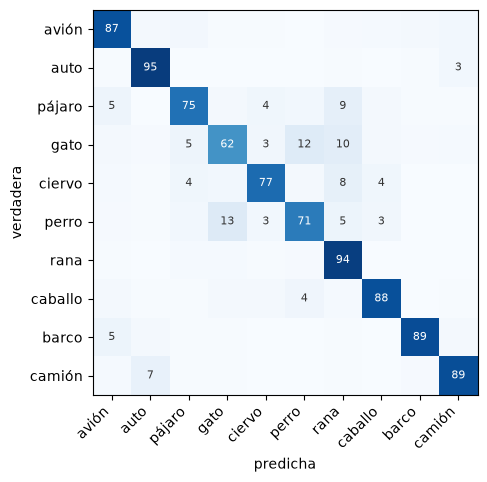

Confusiones más frecuentes: ['perro→gato (13 %)', 'gato→perro (12 %)', 'gato→rana (10 %)']


In [9]:
M = np.array(cnn["cm128_k9"]["confusion"], float); M = 100 * M / M.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(M, cmap="Blues", vmin=0, vmax=100)
for i in range(10):
    for j in range(10):
        if M[i, j] >= 3: ax.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center", fontsize=8, color="white" if M[i, j] > 55 else "#333")
ax.set_xticks(range(10), CLASES, rotation=45, ha="right"); ax.set_yticks(range(10), CLASES)
ax.set(xlabel="predicha", ylabel="verdadera"); plt.show()
peores = sorted(((M[i, j], CLASES[i], CLASES[j]) for i in range(10) for j in range(10) if i != j), reverse=True)[:3]
print("Confusiones más frecuentes:", [f"{a}→{b} ({m:.0f} %)" for m, a, b in peores])

> **🔎 Qué observar.** La diagonal es el acierto por clase. Los errores no se reparten al azar: se concentran entre clases visualmente parecidas. Es una buena señal (el modelo aprendió rasgos con sentido) y también un límite: con $32\times32$ píxeles hay casos ambiguos incluso para una persona.

### 5.5 Filtros aprendidos por el embebido de parches (cf. Apéndice C del artículo)
Los autores observan filtros "tipo Gabor" y manchas de color, como en otras CNN. Se muestran los 64 primeros filtros
$p\times p$ (RGB) del ConvMixer con $p=4$, que son los más fáciles de ver.

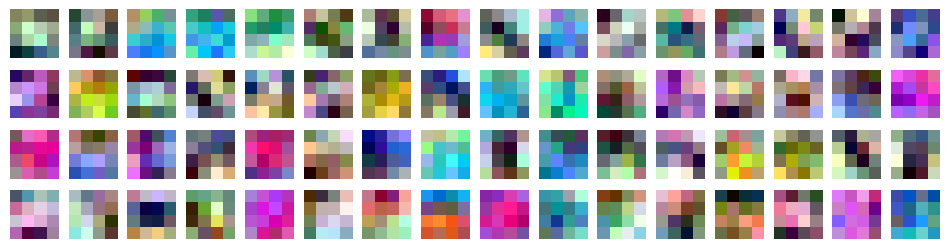

In [10]:
pt = RAIZ / "results" / "cm128_p4.pt"
if pt.exists():
    W = torch.load(pt, map_location="cpu")["0.weight"].numpy().transpose(0, 2, 3, 1)
    W = (W - W.min((1, 2, 3), keepdims=True)) / (np.ptp(W, axis=(1, 2, 3), keepdims=True) + 1e-8)
    fig, axs = plt.subplots(4, 16, figsize=(12, 3))
    for i, a in enumerate(axs.flat): a.imshow(W[i], interpolation="nearest"); a.axis("off")
    plt.show()
else:
    print("Pesos no disponibles (correr en modo completo).")

> **🔎 Qué observar.** Cada cuadradito es un filtro de la primera capa (el embebido de parches). Aparecen bordes orientados y manchas de color, igual que en el Apéndice C del paper y en la corteza visual primaria (U4: origen biológico; Hubel y Wiesel, 1962). La red **aprendió** estos detectores; nadie los programó.

## 6. Los modelos del programa sobre los mismos datos
### 6.1 U1 + U2: seudoinversa con λ elegido por validación cruzada de 5 pliegues
$W=V\,\mathrm{diag}\big(\tfrac{\sigma_i}{\sigma_i^2+\lambda}\big)U^\top T$: una sola SVD por pliegue sirve para todos
los λ.

In [11]:
r = cla["lineal_seudoinversa"]
for l, m, s in zip(r["lambdas"], r["cv_media"], r["cv_desvio"]):
    print(f"λ = {l:>8g}:  CV = {100 * m:5.2f} ± {100 * s:4.2f} %" + ("   ← elegido" if l == r["lambda_cv"] else ""))
print(f"Test (una sola vez): {100 * r['acc_test']:.2f} %")
print(f"Perceptrón simple multiclase (3 semillas): {100 * cla['perceptron']['acc_test']:.2f} %")

λ =        0:  CV = 38.29 ± 0.62 %
λ =       10:  CV = 38.34 ± 0.61 %
λ =      100:  CV = 38.58 ± 0.58 %
λ =     1000:  CV = 39.50 ± 0.44 %
λ =    10000:  CV = 40.54 ± 0.26 %   ← elegido
λ =   100000:  CV = 39.34 ± 0.19 %
Test (una sola vez): 40.67 %
Perceptrón simple multiclase (3 semillas): 40.31 %


> **🔎 Qué observar.** Con $\lambda=0$ (seudoinversa pura) el sistema está mal condicionado y la validación empeora. La regularización de Tikhonov sacrifica un poco de ajuste a cambio de estabilidad, y la validación cruzada elige cuánto sin mirar el test (U1 + U2).
> El perceptrón y la seudoinversa quedan cerca del 40 %: una frontera **lineal** sobre píxeles crudos no alcanza para separar "gato" de "perro".
>
> **💭 Para pensar.** ¿Por qué la exactitud de un clasificador al azar sería del 10 %?

### 6.2 U5: ELM, barrido del número de neuronas ocultas
Pesos de entrada aleatorios y fijos; pesos de salida $\beta=H^+T$ (SVD, Tikhonov con λ elegido en validación).
Sin épocas ni gradiente.

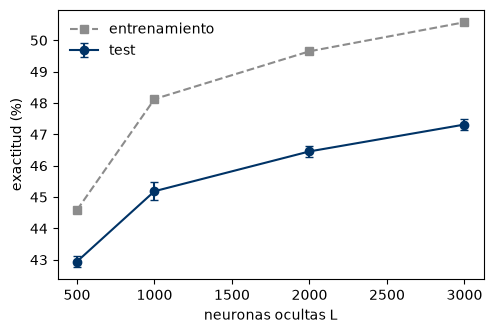

ML-ELM (dos ELM-autoencoders + ELM): 40.41 %


In [12]:
b = cla["elm"]["barrido"]
plt.figure(figsize=(5.5, 3.5))
plt.plot([q["L"] for q in b], [100 * q["acc_entr"] for q in b], "s--", color="#8C8C8C", label="entrenamiento")
plt.errorbar([q["L"] for q in b], [100 * q["acc_test"] for q in b], [100 * q["acc_test_desvio"] for q in b], fmt="o-", color="#003366", capsize=3, label="test")
plt.xlabel("neuronas ocultas L"); plt.ylabel("exactitud (%)"); plt.legend(frameon=False); plt.show()
print(f"ML-ELM (dos ELM-autoencoders + ELM): {100 * cla['ml_elm']['acc_test']:.2f} %")

> **🔎 Qué observar.** Al aumentar $L$ mejoran el entrenamiento y el test, y la brecha entre ambos es chica: con $N=45\,000$ ejemplos y a lo sumo $L=3\,000$ neuronas, el sistema $H\beta=T$ está muy sobredeterminado y casi no hay sobreajuste. Por eso el $\lambda$ elegido en validación varía entre semillas sin que cambie la exactitud (Huang et al., 2012). El sobreajuste aparecería con $L$ cercano a $N$ (ver `estudio/codigo/u5_elm.py`). La ELM mejora a los modelos lineales porque agrega no linealidad, pero sus rasgos son **aleatorios**: no aprovechan que los píxeles vecinos están relacionados.
>
> **💭 Para pensar.** ¿Qué pasaría si, en lugar de píxeles, la ELM recibiera los rasgos del ConvMixer ya entrenado (sin la última capa)?

### 6.3 Demostración en vivo (U5): una ELM se entrena en segundos
Para mostrar la diferencia de costo, se entrena una ELM chica sobre 10 000 imágenes (siempre se ejecuta).

In [13]:
idx = np.random.default_rng(0).permutation(len(x_tr))[:10000]
Xa, Xt = normalizar(x_tr[idx]).reshape(10000, -1), normalizar(x_te).reshape(len(x_te), -1)
t0 = time.time(); elm = ELM(1500, "relu", 10.0, semilla=0).fit(Xa, y_tr[idx]); t = time.time() - t0
print(f"ELM L=1500 sobre 10 000 imágenes: {t:.1f} s de entrenamiento, test = {100 * (elm.predict(Xt) == y_te).mean():.2f} %")

ELM L=1500 sobre 10 000 imágenes: 26.0 s de entrenamiento, test = 40.94 %


> **🔎 Qué observar.** Una ELM se entrena en segundos, con una SVD y sin épocas, mientras que el ConvMixer necesitó casi dos horas. Ese es el atractivo de la U5. El costo es la exactitud: sin rasgos aprendidos, queda lejos de una CNN.

## 7. ¿Y con el cómputo del paper? Réplica en GPU (Google Colab)
Para separar "error de implementación" de "falta de cómputo", corrí el mismo modelo en una GPU gratuita de Google
Colab (Tesla T4) con la **receta oficial de los autores para CIFAR-10** (repositorio
<https://github.com/locuslab/convmixer-cifar10>): ConvMixer-256/8, $k=5$, $p=2$, RandAugment, ColorJitter,
*random erasing*, AdamW y 100 épocas, a unos 55 s por época. El script es `src/colab_receta_paper.py`.
La celda lee el resultado guardado (o el registro parcial, si la sesión gratuita se cortó).

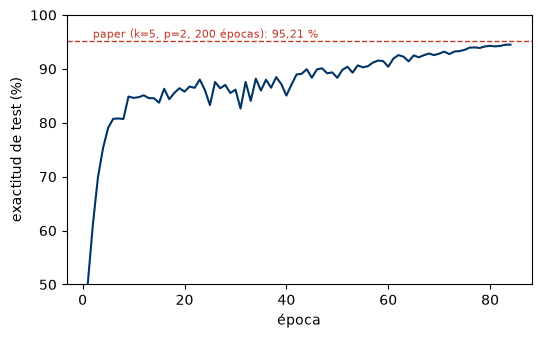

Exactitud de test en la última época: 94.50 % (corrida interrumpida en la época 84 de 100)


In [14]:
import re
f_json, f_log = RAIZ / "results" / "colab_gpu.json", RAIZ / "results" / "colab_gpu_corrida1_log.txt"
if f_json.exists():
    d = json.loads(f_json.read_text(encoding="utf8")); acc = [h["acc_test"] for h in d["historia"]]; nota = "100 épocas completas"
else:
    filas = re.findall(r"época\s+(\d+)/(\d+) \| entr ([\d.]+) \| test ([\d.]+)", f_log.read_text(encoding="utf8"))
    acc = [float(r[3]) for r in filas]; nota = f"corrida interrumpida en la época {len(acc)} de 100"
plt.figure(figsize=(6, 3.5)); plt.plot(range(1, len(acc) + 1), 100 * np.array(acc), color="#003366")
plt.axhline(95.21, color="#C0392B", ls="--", lw=1); plt.text(2, 95.8, "paper (k=5, p=2, 200 épocas): 95,21 %", color="#C0392B", fontsize=8)
plt.ylim(50, 100); plt.xlabel("época"); plt.ylabel("exactitud de test (%)"); plt.show()
print(f"Exactitud de test en la última época: {100 * acc[-1]:.2f} % ({nota})")

> **🔎 Qué observar.** Con la receta completa la exactitud queda a menos de un punto del valor publicado: la
> implementación es correcta y la diferencia de la réplica en CPU se explica por la escala (épocas, tamaño y
> aumentación). La curva se usa sólo para seguir el entrenamiento: se informa la **última** época, no la mejor
> (elegir la mejor mirando el test sería hacer trampa, U1).

## 8. Conclusiones de la réplica
Ver la discusión completa en `informe/TF_informe.pdf`. En síntesis:

1. **La implementación es correcta.** Con la receta de los autores en GPU, el modelo queda cerca del 95,2 % publicado.
2. **Con poco cómputo, ConvMixer ≈ ResNet** (82,7 % frente a 83,0 %), pero la ResNet es unas 3,7 veces más rápida:
   el costo del ConvMixer se reproduce y su ventaja en exactitud no.
3. **Ablaciones:** el efecto del parche se reproduce ($p=4$ pierde 4 puntos); el del núcleo grande, no: con 10
   épocas, $k=3$ rindió 2 puntos más. Con una sola semilla es un indicio, no una conclusión.
4. **Sesgo inductivo:** perceptrón ≈ seudoinversa (≈ 40 %) < ELM (47 %) < MLP (57 %) ≪ CNN (83–85 %). El MLP tiene
   16 veces más parámetros que el ConvMixer y queda 25 puntos abajo: la localidad y los pesos compartidos valen más
   que los parámetros.
5. **Limitaciones:** una semilla por CNN, 10 épocas y un modelo más chico. Las diferencias menores a 1 punto no
   deben sobreinterpretarse.

## Referencias (APA 7)
- Freund, Y. y Schapire, R. E. (1999). Large margin classification using the perceptron algorithm. *Machine Learning, 37*(3), 277–296.
- He, K., Zhang, X., Ren, S. y Sun, J. (2016). Deep residual learning for image recognition. En *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770–778). https://doi.org/10.1109/CVPR.2016.90
- Huang, G.-B., Zhou, H., Ding, X. y Zhang, R. (2012). Extreme learning machine for regression and multiclass classification. *IEEE Transactions on Systems, Man, and Cybernetics, Part B, 42*(2), 513–529.
- Huang, G.-B., Zhu, Q.-Y. y Siew, C.-K. (2006). Extreme learning machine: Theory and applications. *Neurocomputing, 70*(1–3), 489–501. https://doi.org/10.1016/j.neucom.2005.12.126
- Hubel, D. H. y Wiesel, T. N. (1962). Receptive fields, binocular interaction and functional architecture in the cat's visual cortex. *The Journal of Physiology, 160*(1), 106–154.
- Kasun, L. L. C., Zhou, H., Huang, G.-B. y Vong, C. M. (2013). Representational learning with ELMs for big data. *IEEE Intelligent Systems, 28*(6), 31–34.
- Krizhevsky, A. (2009). *Learning multiple layers of features from tiny images* [Informe técnico]. University of Toronto. https://www.cs.toronto.edu/~kriz/cifar-10.html
- Loshchilov, I. y Hutter, F. (2019). Decoupled weight decay regularization. En *International Conference on Learning Representations*. https://doi.org/10.48550/arXiv.1711.05101
- Trockman, A. y Kolter, J. Z. (2023). Patches are all you need? *Transactions on Machine Learning Research*. https://doi.org/10.48550/arXiv.2201.09792